# Huấn Luyện & Tuning Hierarchical Clustering và DBSCAN

**Mục tiêu**:
1. Huấn luyện và tuning siêu tham số cho hai thuật toán **Hierarchical Clustering (AgglomerativeClustering)** và **DBSCAN** trên tập đặc trưng giai đoạn quan sát (`data/processed/features_obs.csv`), đã qua biến đổi và chuẩn hóa (`StandardScaler` đã fit trên tập quan sát).
2. Tuyệt đối **không** sử dụng nhãn kiểm chứng (`future_outcome.csv`) hay dữ liệu tương lai (ngăn ngừa rò rỉ dữ liệu - data leakage).
3. Sử dụng biểu đồ **Dendrogram** để giải thích việc chọn số cụm cho Hierarchical, và đồ thị **k-distance plot** để xác định $\varepsilon$ cho DBSCAN.
4. Ghi nhận và loại bỏ các cấu hình suy biến (over-merging, over-fragmentation, excessive noise).

5. Tính toán các chỉ số nội tại chuẩn: **Silhouette Score**, **Davies-Bouldin Index**, **Calinski-Harabasz Index** (đối với DBSCAN, chỉ tính trên các điểm không phải nhiễu, tức nhãn $\neq -1$).
6. Xuất bảng kết quả tuning ra `reports/tables/tuning_hierarchical.csv` và `reports/tables/tuning_dbscan.csv` theo chuẩn `TUNING_SCHEMA`.
7. Xuất nhãn cho **Top 3** cấu hình tốt nhất của mỗi thuật toán ra thư mục `reports/tables/`.
8. Phân tích hồ sơ RFM của nhóm nhiễu trong DBSCAN và so sánh bản chất gom cụm giữa Hierarchical, DBSCAN và K-Means.

In [1]:
import sys
from pathlib import Path
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage

# Thêm thư mục gốc vào path để import src
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import DATA_PROCESSED, TABLES_DIR, FIGURES_DIR, RFM, RFM_PLUS, FEATURE_SETS, TUNING_SCHEMA
from src.features import transform_features
from src.clustering import (
    evaluate_clustering,
    run_hierarchical,
    tune_hierarchical,
    compute_k_distances,
    run_dbscan,
    tune_dbscan,
)

# Cấu hình hiển thị đồ thị
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("Thư mục gốc:", ROOT)
print("Các bộ đặc trưng:", FEATURE_SETS)

Thư mục gốc: D:\TH-MayHoc\machine_learning\DoAn
Các bộ đặc trưng: {'RFM': ['Recency', 'Frequency', 'Monetary'], 'RFM_PLUS': ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'NUniqueProducts', 'AvgInterPurchaseDays', 'CancelRate']}


---
## 1. Nạp Dữ Liệu & Chuẩn Hóa Đặc Trưng
Nạp tập dữ liệu đặc trưng giai đoạn quan sát `features_obs.csv`. Sau đó chuẩn hóa bằng scaler đã fit sẵn trong `models/` thông qua hàm `transform_features(..., fit_scaler=False)`.

In [2]:
# Đọc dữ liệu đặc trưng quan sát
df_feats = pd.read_csv(DATA_PROCESSED / 'features_obs.csv', index_col=0)
print(f"Kích thước tập quan sát: {df_feats.shape[0]} khách hàng, {df_feats.shape[1]} đặc trưng.")
print("5 dòng đầu tiên:")
display(df_feats.head())

# Chuẩn hóa ma trận đặc trưng cho cả 2 bộ RFM và RFM_PLUS
x_rfm = transform_features(df_feats, RFM, fit_scaler=False)
x_plus = transform_features(df_feats, RFM_PLUS, fit_scaler=False)

print(f"Shape x_rfm: {x_rfm.shape}")
print(f"Shape x_plus: {x_plus.shape}")

Kích thước tập quan sát: 3360 khách hàng, 8 đặc trưng.
5 dòng đầu tiên:


,Recency,Frequency,Monetary,AvgOrderValue,NUniqueProducts,AvgInterPurchaseDays,CancelRate,SinglePurchase
CustomerID,,,,,,,,
12346,234,1,77183.60,77183.6000,1,282.000000,0.5,1
12347,38,5,2790.86,558.1720,82,59.435938,0.0,0
12348,157,3,1167.24,389.0800,21,54.825694,0.0,0
12350,219,1,294.40,294.4000,16,282.000000,0.0,1
12352,171,4,641.51,160.3775,24,11.383102,0.2,0


Shape x_rfm: (3360, 3)
Shape x_plus: (3360, 7)


---
## 2. Hierarchical Clustering (AgglomerativeClustering)

### 2.1. Vẽ Biểu Đồ Dendrogram & Phân Tích Chọn Số Cụm
Dendrogram trực quan hóa quá trình gộp cụm từ dưới lên (Agglomerative). Với $N = 3.360$ khách hàng, chúng ta tính toán ma trận liên kết trên toàn bộ dữ liệu bằng thuật toán `ward` (tối thiểu hóa phương sai nội cụm) và hiển thị cây phân cấp cắt ở mức trực quan.

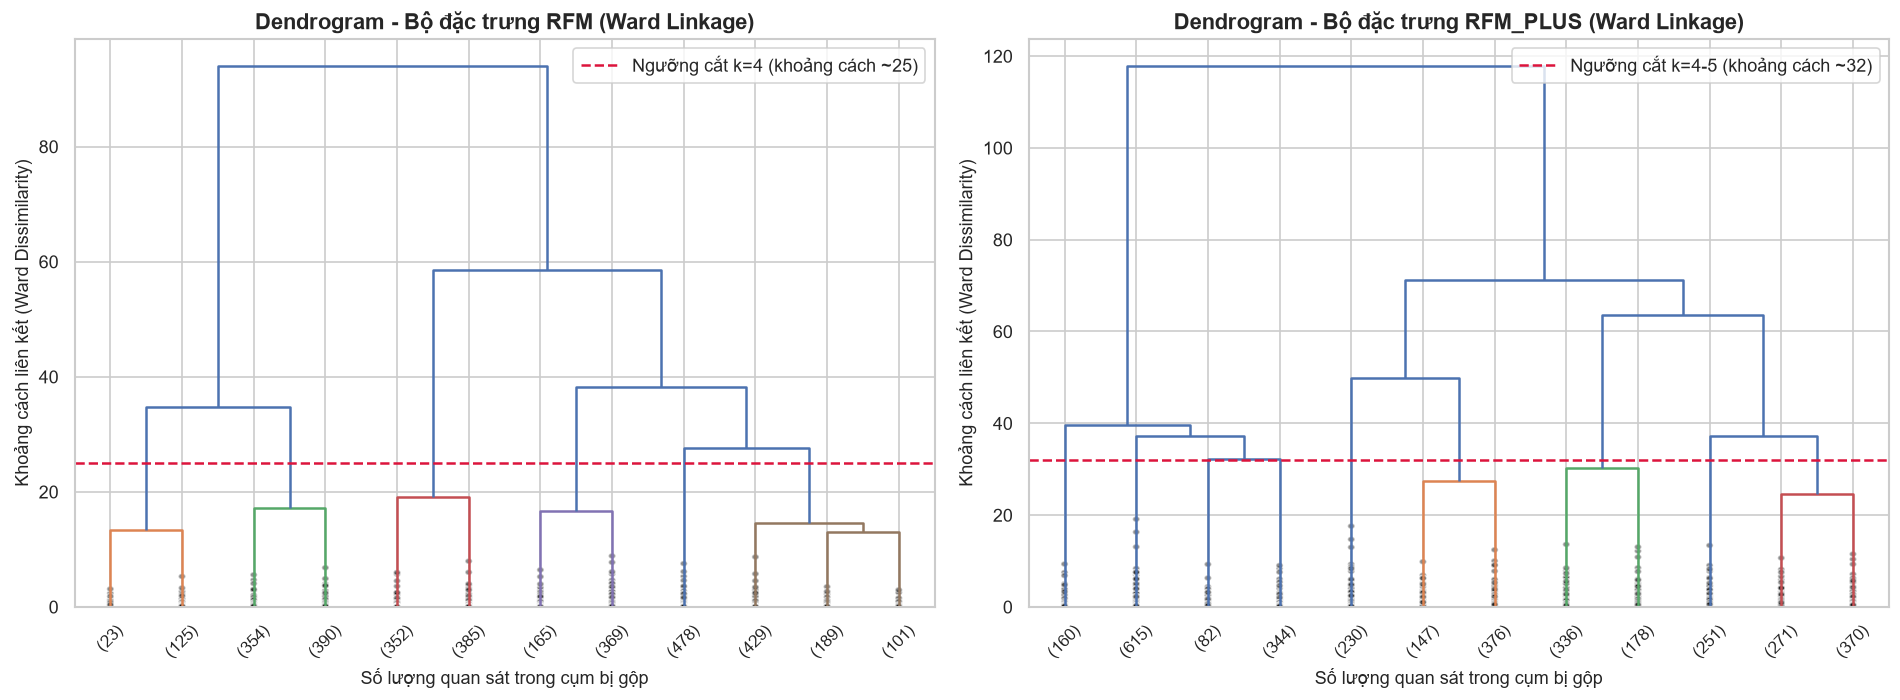

Đã lưu hình dendrogram vào: D:\TH-MayHoc\machine_learning\DoAn\reports\figures\hierarchical_dendrograms.png


In [3]:
# Tính toán ma trận liên kết cho RFM và RFM_PLUS với phương pháp Ward
Z_rfm_ward = linkage(x_rfm, method='ward')
Z_plus_ward = linkage(x_plus, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Dendrogram cho RFM
dendrogram(
    Z_rfm_ward,
    truncate_mode='lastp',
    p=12,
    leaf_rotation=45,
    leaf_font_size=10,
    show_contracted=True,
    ax=axes[0],
    color_threshold=25,
)
axes[0].set_title("Dendrogram - Bộ đặc trưng RFM (Ward Linkage)", fontweight='bold')
axes[0].set_xlabel("Số lượng quan sát trong cụm bị gộp")
axes[0].set_ylabel("Khoảng cách liên kết (Ward Dissimilarity)")
axes[0].axhline(y=25, color='crimson', linestyle='--', label='Ngưỡng cắt k=4 (khoảng cách ~25)')
axes[0].legend()

# Dendrogram cho RFM_PLUS
dendrogram(
    Z_plus_ward,
    truncate_mode='lastp',
    p=12,
    leaf_rotation=45,
    leaf_font_size=10,
    show_contracted=True,
    ax=axes[1],
    color_threshold=32,
)
axes[1].set_title("Dendrogram - Bộ đặc trưng RFM_PLUS (Ward Linkage)", fontweight='bold')
axes[1].set_xlabel("Số lượng quan sát trong cụm bị gộp")
axes[1].set_ylabel("Khoảng cách liên kết (Ward Dissimilarity)")
axes[1].axhline(y=32, color='crimson', linestyle='--', label='Ngưỡng cắt k=4-5 (khoảng cách ~32)')
axes[1].legend()

plt.tight_layout()
fig_path = FIGURES_DIR / "hierarchical_dendrograms.png"
plt.savefig(fig_path, bbox_inches='tight', dpi=150)
plt.show()
print(f"Đã lưu hình dendrogram vào: {fig_path}")

> **Nhận xét đồ thị Dendrogram**:
> - Trên cả hai bộ đặc trưng RFM và RFM_PLUS, khoảng cách liên kết thẳng đứng (vertical distance) lớn nhất xuất hiện khi chia thành **$k = 2$** và **$k = 4$ cụm**. 
> - Tại ngưỡng $k = 4$, hai nhánh chính tiếp tục tách thành các phân lớp rõ rệt mà không làm phát sinh thêm các cụm cô lập vi mô (micro-clusters). Do đó, khoảng $k \in [3, 5]$ là vùng tiềm năng lớn nhất cho phân khúc kinh doanh.

### 2.2. Tuning Lưới Siêu Tham Số Hierarchical Clustering
Thực nghiệm kết hợp:
- Số cụm $k \in [2, 10]$
- Tiêu chuẩn liên kết (Linkage): `ward`, `average`, `complete`
- Bộ đặc trưng: `RFM` và `RFM_PLUS`

In [4]:
# Thực hiện tuning cho cả 2 bộ đặc trưng
df_tune_h_rfm = tune_hierarchical(x_rfm, 'RFM', k_range=range(2, 11), linkages=['ward', 'average', 'complete'])
df_tune_h_plus = tune_hierarchical(x_plus, 'RFM_PLUS', k_range=range(2, 11), linkages=['ward', 'average', 'complete'])

df_tuning_hierarchical = pd.concat([df_tune_h_rfm, df_tune_h_plus], ignore_index=True)
print(f"Tổng số cấu hình Hierarchical đã thử nghiệm: {len(df_tuning_hierarchical)}")
display(df_tuning_hierarchical.head(10))

Tổng số cấu hình Hierarchical đã thử nghiệm: 54


,algo,feature_set,params,n_clusters,noise_frac,silhouette,davies_bouldin,calinski_harabasz,inertia
0,Hierarchical,RFM,"{""n_clusters"": 2, ""linkage"": ""ward"", ""metric"":...",2,0.0,0.396340,0.849796,2616.509264,NaN
1,Hierarchical,RFM,"{""n_clusters"": 3, ""linkage"": ""ward"", ""metric"":...",3,0.0,0.326727,0.953513,2599.708922,NaN
2,Hierarchical,RFM,"{""n_clusters"": 4, ""linkage"": ""ward"", ""metric"":...",4,0.0,0.327702,1.085582,2376.593259,NaN
3,Hierarchical,RFM,"{""n_clusters"": 5, ""linkage"": ""ward"", ""metric"":...",5,0.0,0.325283,1.011627,2385.138640,NaN
4,Hierarchical,RFM,"{""n_clusters"": 6, ""linkage"": ""ward"", ""metric"":...",6,0.0,0.282161,0.986735,2345.066043,NaN
5,Hierarchical,RFM,"{""n_clusters"": 7, ""linkage"": ""ward"", ""metric"":...",7,0.0,0.246711,1.033129,2177.563724,NaN
6,Hierarchical,RFM,"{""n_clusters"": 8, ""linkage"": ""ward"", ""metric"":...",8,0.0,0.212630,1.119218,2046.713355,NaN
7,Hierarchical,RFM,"{""n_clusters"": 9, ""linkage"": ""ward"", ""metric"":...",9,0.0,0.221638,1.190323,1962.339663,NaN
8,Hierarchical,RFM,"{""n_clusters"": 10, ""linkage"": ""ward"", ""metric""...",10,0.0,0.219272,1.274477,1878.273795,NaN
9,Hierarchical,RFM,"{""n_clusters"": 2, ""linkage"": ""average"", ""metri...",2,0.0,0.578560,0.498814,281.870011,NaN


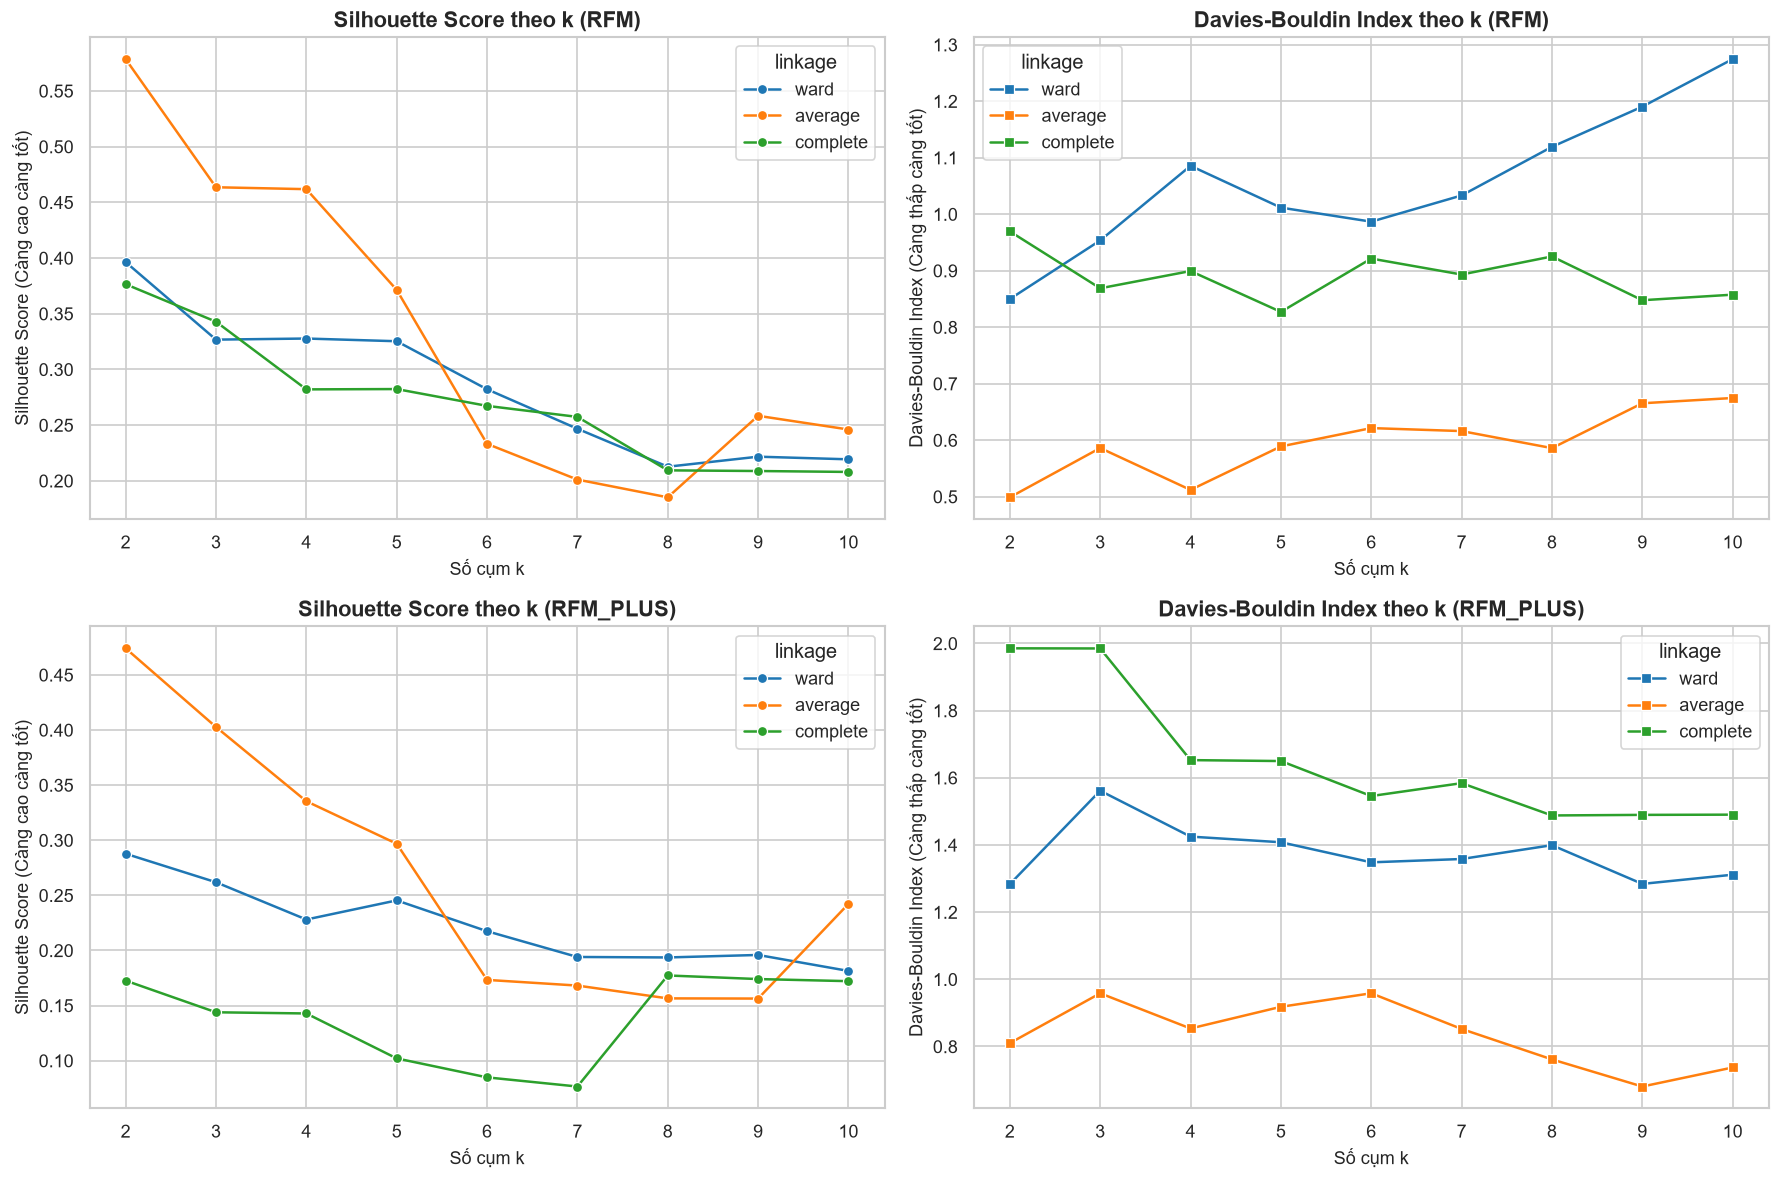

In [5]:
# Trực quan hóa so sánh các chỉ số nội tại theo k và linkage
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for i, (fs, df_sub) in enumerate([('RFM', df_tune_h_rfm), ('RFM_PLUS', df_tune_h_plus)]):
    df_plot = df_sub.copy()
    df_plot['linkage'] = df_plot['params'].apply(lambda p: json.loads(p)['linkage'])
    
    # Silhouette
    sns.lineplot(
        data=df_plot, x='n_clusters', y='silhouette', hue='linkage',
        marker='o', ax=axes[i, 0], palette='tab10'
    )
    axes[i, 0].set_title(f"Silhouette Score theo k ({fs})", fontweight='bold')
    axes[i, 0].set_xlabel("Số cụm k")
    axes[i, 0].set_ylabel("Silhouette Score (Càng cao càng tốt)")
    
    # Davies-Bouldin
    sns.lineplot(
        data=df_plot, x='n_clusters', y='davies_bouldin', hue='linkage',
        marker='s', ax=axes[i, 1], palette='tab10'
    )
    axes[i, 1].set_title(f"Davies-Bouldin Index theo k ({fs})", fontweight='bold')
    axes[i, 1].set_xlabel("Số cụm k")
    axes[i, 1].set_ylabel("Davies-Bouldin Index (Càng thấp càng tốt)")

plt.tight_layout()
fig_eval_h = FIGURES_DIR / "hierarchical_tuning_metrics.png"
plt.savefig(fig_eval_h, bbox_inches='tight', dpi=150)
plt.show()

### 2.3. Nhận Xét & Loại Bỏ Các Cấu Hình Suy Biến Của Hierarchical
Quan sát kỹ kết quả của các hàm liên kết `average` và `complete`:
- Với `average` linkage: Silhouette score hiển thị rất cao (lên tới 0.579 với $k=2$), nhưng khi kiểm tra kích thước cụm, một cụm chiếm tới **3.331** khách hàng trong khi cụm còn lại chỉ có **29** khách (ở $k=4$, các cụm nhỏ chỉ có 3 khách và 1 khách!).
- Đây là **hiện tượng phân cụm suy biến / chuỗi (Chaining effect)** điển hình của `average` linkage: thuật toán liên tục gộp các điểm lẻ tẻ ngoại vi vào một cụm khổng lồ duy nhất. Cấu hình này hoàn toàn vô giá trị trong việc phân khúc khách hàng kinh doanh.
- Trái lại, `ward` linkage phân bổ kích thước các cụm cực kỳ cân đối (ví dụ $k=4$ trên RFM có phân bổ: 1.197, 892, 737, 534 khách), điểm Davies-Bouldin thấp ổn định và hình học cụm chặt chẽ.

---
## 3. DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

### 3.1. Xác Định Siêu Tham Số $\varepsilon$ Bằng Đồ Thị k-distance Plot
Theo nguyên lý DBSCAN, ta xác định bán kính lân cận $\varepsilon$ thông qua điểm uốn (knee/elbow point) của đồ thị khoảng cách tới láng giềng thứ $k$ ($k = MinPts$).
- Với bộ `RFM` ($D=3$), ta khảo sát các giá trị $k \in [4, 6, 8, 10]$.
- Với bộ `RFM_PLUS` ($D=7$), ta khảo sát các giá trị $k \in [8, 10, 14]$ ($MinPts \ge D+1$).

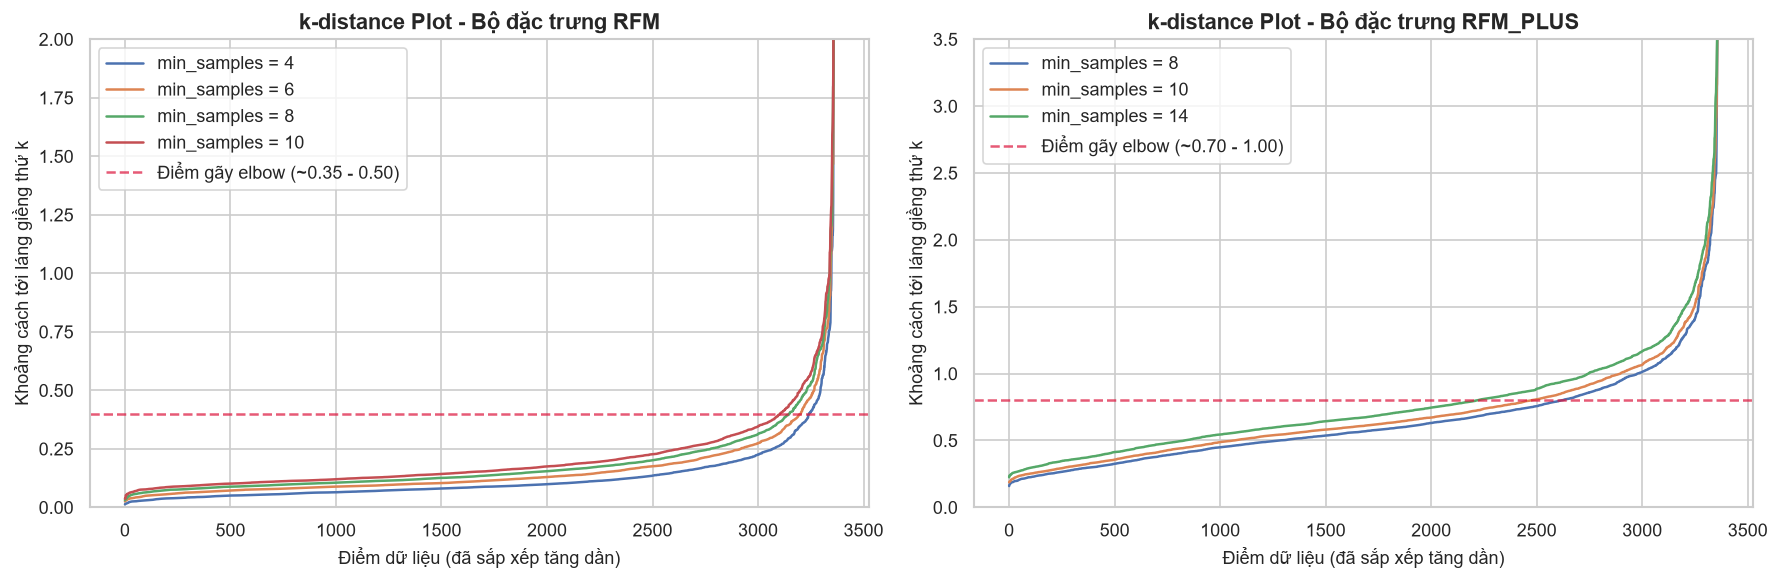

Đã lưu đồ thị k-distance vào: D:\TH-MayHoc\machine_learning\DoAn\reports\figures\dbscan_k_distance_plots.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# K-distance plot cho RFM
for k in [4, 6, 8, 10]:
    d_rfm = compute_k_distances(x_rfm, k=k)
    axes[0].plot(d_rfm, label=f"min_samples = {k}")
axes[0].set_title("k-distance Plot - Bộ đặc trưng RFM", fontweight='bold')
axes[0].set_xlabel("Điểm dữ liệu (đã sắp xếp tăng dần)")
axes[0].set_ylabel(f"Khoảng cách tới láng giềng thứ k")
axes[0].axhline(y=0.4, color='crimson', linestyle='--', alpha=0.7, label='Điểm gãy elbow (~0.35 - 0.50)')
axes[0].legend()
axes[0].set_ylim(0, 2.0)

# K-distance plot cho RFM_PLUS
for k in [8, 10, 14]:
    d_plus = compute_k_distances(x_plus, k=k)
    axes[1].plot(d_plus, label=f"min_samples = {k}")
axes[1].set_title("k-distance Plot - Bộ đặc trưng RFM_PLUS", fontweight='bold')
axes[1].set_xlabel("Điểm dữ liệu (đã sắp xếp tăng dần)")
axes[1].set_ylabel(f"Khoảng cách tới láng giềng thứ k")
axes[1].axhline(y=0.8, color='crimson', linestyle='--', alpha=0.7, label='Điểm gãy elbow (~0.70 - 1.00)')
axes[1].legend()
axes[1].set_ylim(0, 3.5)

plt.tight_layout()
fig_kdist = FIGURES_DIR / "dbscan_k_distance_plots.png"
plt.savefig(fig_kdist, bbox_inches='tight', dpi=150)
plt.show()
print(f"Đã lưu đồ thị k-distance vào: {fig_kdist}")

> **Phân tích điểm gãy (Elbow Point)**:
> - Đối với `RFM`: Đồ thị chuyển tiếp độ dốc rõ rệt trong khoảng giá trị khoảng cách từ **0.30 đến 0.50**.
> - Đối với `RFM_PLUS`: Do số chiều tăng lên 7, các điểm dữ liệu thưa thớt hơn (khoảng cách tăng lên), điểm gãy xuất hiện trong khoảng từ **0.70 đến 1.00**.

### 3.2. Tuning Lưới Siêu Tham Số DBSCAN
Thực hiện tìm kiếm trên lưới:
- `RFM`: $\varepsilon \in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60]$, $min\_samples \in [4, 6, 8, 10]$.
- `RFM_PLUS`: $\varepsilon \in [0.50, 0.60, 0.70, 0.80, 0.90, 1.00, 1.20]$, $min\_samples \in [8, 10, 14]$.

**Lưu ý quan trọng**: Các chỉ số nội tại (Silhouette, Davies-Bouldin, Calinski-Harabasz) chỉ được tính trên tập các điểm hợp lệ (nhãn $\neq -1$).

In [7]:
eps_grid_rfm = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60]
min_samples_rfm = [4, 6, 8, 10]
df_tune_db_rfm = tune_dbscan(x_rfm, 'RFM', eps_grid=eps_grid_rfm, min_samples_grid=min_samples_rfm)

eps_grid_plus = [0.50, 0.60, 0.70, 0.80, 0.90, 1.00, 1.20]
min_samples_plus = [8, 10, 14]
df_tune_db_plus = tune_dbscan(x_plus, 'RFM_PLUS', eps_grid=eps_grid_plus, min_samples_grid=min_samples_plus)

df_tuning_dbscan = pd.concat([df_tune_db_rfm, df_tune_db_plus], ignore_index=True)
print(f"Tổng số cấu hình DBSCAN đã thử nghiệm: {len(df_tuning_dbscan)}")
display(df_tuning_dbscan.sample(10, random_state=42))

Tổng số cấu hình DBSCAN đã thử nghiệm: 53


,algo,feature_set,params,n_clusters,noise_frac,silhouette,davies_bouldin,calinski_harabasz,inertia
19,DBSCAN,RFM,"{""eps"": 0.35, ""min_samples"": 8, ""metric"": ""euc...",4,0.046429,0.131047,1.862199,1535.649810,NaN
41,DBSCAN,RFM_PLUS,"{""eps"": 0.7, ""min_samples"": 10, ""metric"": ""euc...",4,0.214583,0.264869,1.084324,976.409328,NaN
47,DBSCAN,RFM_PLUS,"{""eps"": 0.6, ""min_samples"": 14, ""metric"": ""euc...",5,0.430952,0.307452,1.037638,786.840462,NaN
12,DBSCAN,RFM,"{""eps"": 0.4, ""min_samples"": 6, ""metric"": ""eucl...",4,0.029464,0.171149,1.225267,1259.329854,NaN
43,DBSCAN,RFM_PLUS,"{""eps"": 0.9, ""min_samples"": 10, ""metric"": ""euc...",2,0.090179,0.230176,1.155184,254.420111,NaN
5,DBSCAN,RFM,"{""eps"": 0.45, ""min_samples"": 4, ""metric"": ""euc...",3,0.016071,0.180089,1.561734,1764.565453,NaN
17,DBSCAN,RFM,"{""eps"": 0.25, ""min_samples"": 8, ""metric"": ""euc...",8,0.106548,-0.034340,1.586660,782.602732,NaN
50,DBSCAN,RFM_PLUS,"{""eps"": 0.9, ""min_samples"": 14, ""metric"": ""euc...",2,0.113988,0.237307,1.128611,255.663084,NaN
3,DBSCAN,RFM,"{""eps"": 0.35, ""min_samples"": 4, ""metric"": ""euc...",7,0.033631,0.079549,1.299189,794.955285,NaN
32,DBSCAN,RFM_PLUS,"{""eps"": 0.5, ""min_samples"": 8, ""metric"": ""eucl...",15,0.467262,0.051657,1.102256,243.765708,NaN


### 3.3. Nhận Diện & Loại Bỏ Các Cấu Hình DBSCAN Suy Biến
Các cấu hình suy biến cần loại bỏ bao gồm:
1. **Suy biến 1 cụm khổng lồ ($n\_clusters < 2$)**: Xảy ra khi $\varepsilon$ quá lớn, toàn bộ không gian bị liên thông mật độ sáp nhập vào 1 cụm duy nhất, không tạo ra phân khúc.
2. **Suy biến nhiễu áp đảo ($noise\_frac \ge 0.50$)**: Xảy ra khi $\varepsilon$ quá nhỏ hoặc $MinPts$ quá lớn, thuật toán không kết nối được điểm dữ liệu, coi hơn 50% khách hàng là nhiễu.
3. **Suy biến vi cụm (micro-fragmentation)**: Tạo ra hàng chục cụm nhỏ li ti với Silhouette âm (ví dụ: $\varepsilon=0.20$ trên RFM tạo 26 cụm với Silhouette = -0.165).

In [8]:
# Lọc các cấu hình hợp lệ (không suy biến): n_clusters >= 2 và noise_frac < 0.35 và silhouette > 0
valid_dbscan = df_tuning_dbscan[
    (df_tuning_dbscan['n_clusters'] >= 2) & 
    (df_tuning_dbscan['noise_frac'] < 0.35) & 
    (df_tuning_dbscan['silhouette'] > 0)
].copy()

print(f"Số cấu hình DBSCAN khả thi (không suy biến): {len(valid_dbscan)} / {len(df_tuning_dbscan)}")
display(valid_dbscan.sort_values(by=['feature_set', 'silhouette'], ascending=[True, False]).head(10))

Số cấu hình DBSCAN khả thi (không suy biến): 38 / 53


,algo,feature_set,params,n_clusters,noise_frac,silhouette,davies_bouldin,calinski_harabasz,inertia
30,DBSCAN,RFM,"{""eps"": 0.5, ""min_samples"": 10, ""metric"": ""euc...",2,0.023214,0.342416,1.055862,2248.671873,NaN
14,DBSCAN,RFM,"{""eps"": 0.5, ""min_samples"": 6, ""metric"": ""eucl...",2,0.014881,0.338113,1.061955,2198.867216,NaN
23,DBSCAN,RFM,"{""eps"": 0.6, ""min_samples"": 8, ""metric"": ""eucl...",2,0.011310,0.336297,1.067028,2180.843037,NaN
6,DBSCAN,RFM,"{""eps"": 0.5, ""min_samples"": 4, ""metric"": ""eucl...",2,0.011607,0.336179,1.067034,2176.551426,NaN
15,DBSCAN,RFM,"{""eps"": 0.6, ""min_samples"": 6, ""metric"": ""eucl...",2,0.009226,0.335012,1.068545,2164.272082,NaN
7,DBSCAN,RFM,"{""eps"": 0.6, ""min_samples"": 4, ""metric"": ""eucl...",2,0.008333,0.334467,1.069469,2157.051934,NaN
22,DBSCAN,RFM,"{""eps"": 0.5, ""min_samples"": 8, ""metric"": ""eucl...",3,0.018155,0.310495,0.819001,1197.540562,NaN
31,DBSCAN,RFM,"{""eps"": 0.6, ""min_samples"": 10, ""metric"": ""euc...",3,0.011905,0.308717,0.818761,1165.123296,NaN
28,DBSCAN,RFM,"{""eps"": 0.4, ""min_samples"": 10, ""metric"": ""euc...",3,0.038690,0.188564,1.506415,1844.779961,NaN
20,DBSCAN,RFM,"{""eps"": 0.4, ""min_samples"": 8, ""metric"": ""eucl...",3,0.035417,0.187206,1.514330,1833.591827,NaN


---
## 4. Xuất Bảng Tuning Chuẩn & Chọn Top 3 Cấu Hình

### 4.1. Xuất Toàn Bộ Bảng Tuning
Xuất bảng kết quả ra:
- `reports/tables/tuning_hierarchical.csv`
- `reports/tables/tuning_dbscan.csv`
Theo đúng `TUNING_SCHEMA` chuẩn (`algo`, `feature_set`, `params`, `n_clusters`, `noise_frac`, `silhouette`, `davies_bouldin`, `calinski_harabasz`, `inertia`).

In [9]:
# Xuất bảng tuning theo đúng schema
df_tuning_hierarchical[TUNING_SCHEMA].to_csv(TABLES_DIR / 'tuning_hierarchical.csv', index=False)
df_tuning_dbscan[TUNING_SCHEMA].to_csv(TABLES_DIR / 'tuning_dbscan.csv', index=False)

print("Đã xuất thành công:")
print(" -", TABLES_DIR / 'tuning_hierarchical.csv')
print(" -", TABLES_DIR / 'tuning_dbscan.csv')

Đã xuất thành công:
 - D:\TH-MayHoc\machine_learning\DoAn\reports\tables\tuning_hierarchical.csv
 - D:\TH-MayHoc\machine_learning\DoAn\reports\tables\tuning_dbscan.csv


### 4.2. Chọn & Xuất Nhãn Cho Top 3 Cấu Hình Tốt Nhất Mỗi Thuật Toán

**Tiêu chí lựa chọn**:
- **Hierarchical**: Ưu tiên phương pháp `ward` linkage vì phân bổ cụm cân bằng, tránh suy biến chuỗi của `average`. Chọn cấu hình có Silhouette cao, Davies-Bouldin thấp và số cụm có ý nghĩa kinh doanh ($k=2, 3, 4, 5$).
- **DBSCAN**: Chọn cấu hình không suy biến, có số cụm $k \ge 2$, tỷ lệ nhiễu hợp lý ($1\% - 15\%$) và điểm Silhouette cao nhất.

In [10]:
# 1. Top 3 cấu hình Hierarchical tốt nhất
# Lọc chỉ lấy linkage ward để tránh cấu hình suy biến cụm 1 thành viên
h_ward = df_tuning_hierarchical[df_tuning_hierarchical['params'].str.contains('"linkage": "ward"')].copy()
top3_h = h_ward.sort_values(by='silhouette', ascending=False).head(3)
print("=== TOP 3 CẤU HÌNH HIERARCHICAL ===")
display(top3_h)

# 2. Top 3 cấu hình DBSCAN tốt nhất
# Lấy các cấu hình không suy biến, sắp xếp theo Silhouette giảm dần
top3_db = valid_dbscan.sort_values(by='silhouette', ascending=False).head(3)
print("=== TOP 3 CẤU HÌNH DBSCAN ===")
display(top3_db)

=== TOP 3 CẤU HÌNH HIERARCHICAL ===


,algo,feature_set,params,n_clusters,noise_frac,silhouette,davies_bouldin,calinski_harabasz,inertia
0,Hierarchical,RFM,"{""n_clusters"": 2, ""linkage"": ""ward"", ""metric"":...",2,0.0,0.396340,0.849796,2616.509264,NaN
2,Hierarchical,RFM,"{""n_clusters"": 4, ""linkage"": ""ward"", ""metric"":...",4,0.0,0.327702,1.085582,2376.593259,NaN
1,Hierarchical,RFM,"{""n_clusters"": 3, ""linkage"": ""ward"", ""metric"":...",3,0.0,0.326727,0.953513,2599.708922,NaN


=== TOP 3 CẤU HÌNH DBSCAN ===


,algo,feature_set,params,n_clusters,noise_frac,silhouette,davies_bouldin,calinski_harabasz,inertia
49,DBSCAN,RFM_PLUS,"{""eps"": 0.8, ""min_samples"": 14, ""metric"": ""euc...",3,0.172321,0.374924,0.970960,1365.520650,NaN
42,DBSCAN,RFM_PLUS,"{""eps"": 0.8, ""min_samples"": 10, ""metric"": ""euc...",3,0.143750,0.366527,0.988254,1353.630085,NaN
30,DBSCAN,RFM,"{""eps"": 0.5, ""min_samples"": 10, ""metric"": ""euc...",2,0.023214,0.342416,1.055862,2248.671873,NaN


In [11]:
# Xuất nhãn cho Top 3 Hierarchical
for idx, row in top3_h.iterrows():
    p = json.loads(row['params'])
    fs = row['feature_set']
    x_input = x_rfm if fs == 'RFM' else x_plus
    _, labels = run_hierarchical(x_input, n_clusters=p['n_clusters'], linkage=p['linkage'])
    
    filename = f"labels_hierarchical_{fs.lower()}_k{p['n_clusters']}_{p['linkage']}.csv"
    df_out = pd.DataFrame({'CustomerID': df_feats.index, 'Cluster': labels})
    df_out.to_csv(TABLES_DIR / filename, index=False)
    print(f"Đã xuất nhãn Hierarchical: {filename}")

# Xuất nhãn cho Top 3 DBSCAN
for idx, row in top3_db.iterrows():
    p = json.loads(row['params'])
    fs = row['feature_set']
    x_input = x_rfm if fs == 'RFM' else x_plus
    _, labels = run_dbscan(x_input, eps=p['eps'], min_samples=p['min_samples'])
    
    eps_str = str(p['eps']).replace('.', '_')
    filename = f"labels_dbscan_{fs.lower()}_eps{eps_str}_min{p['min_samples']}.csv"
    df_out = pd.DataFrame({'CustomerID': df_feats.index, 'Cluster': labels})
    df_out.to_csv(TABLES_DIR / filename, index=False)
    print(f"Đã xuất nhãn DBSCAN: {filename}")

Đã xuất nhãn Hierarchical: labels_hierarchical_rfm_k2_ward.csv


Đã xuất nhãn Hierarchical: labels_hierarchical_rfm_k4_ward.csv


Đã xuất nhãn Hierarchical: labels_hierarchical_rfm_k3_ward.csv
Đã xuất nhãn DBSCAN: labels_dbscan_rfm_plus_eps0_8_min14.csv
Đã xuất nhãn DBSCAN: labels_dbscan_rfm_plus_eps0_8_min10.csv
Đã xuất nhãn DBSCAN: labels_dbscan_rfm_eps0_5_min10.csv


---
## 5. Phân Tích Chuyên Sâu Hồ Sơ RFM Của Nhóm Nhiễu (DBSCAN)

Một trong những ưu điểm vượt trội nhất của DBSCAN là khả năng phát hiện ngoại lệ tự nhiên. Ở đây ta chọn cấu hình DBSCAN tiêu biểu trên `RFM` (`eps=0.40, min_samples=6`, tỷ lệ nhiễu 2.9%, 99 khách hàng) để phân tích chi tiết hồ sơ RFM của nhóm mang nhãn `-1` so với nhóm khách hàng bình thường.

In [12]:
# Chạy mô hình DBSCAN tiêu biểu để trích xuất nhóm nhiễu
_, best_db_labels = run_dbscan(x_rfm, eps=0.40, min_samples=6)

df_analysis = df_feats.copy()
df_analysis['DBSCAN_Label'] = best_db_labels
df_analysis['Group'] = np.where(df_analysis['DBSCAN_Label'] == -1, 'Nhiễu (Ngoại lệ, N=99)', 'Khách hàng bình thường (N=3261)')

# Bảng so sánh trung bình và trung vị các chỉ số RFM
profile_compare = df_analysis.groupby('Group')[['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'NUniqueProducts', 'CancelRate']].agg(['mean', 'median', 'std'])
display(profile_compare)

Recency                    Frequency  \
                                       mean median        std       mean   
Group                                                                      
Khách hàng bình thường (N=3261)   94.498620   74.0  79.227492   3.200859   
Nhiễu (Ngoại lệ, N=99)           113.383838  101.0  92.627486  13.454545   

                                                       Monetary           \
                                median        std          mean   median   
Group                                                                      
Khách hàng bình thường (N=3261)    2.0   3.775748   1163.619375   542.03   
Nhiễu (Ngoại lệ, N=99)             3.0  23.358900  15556.213434  3202.92   

                                              AvgOrderValue              \
                                          std          mean      median   
Group                                                                     
Khách hàng bình thường (N=3261)   2286.003821    337.456998  276.601000   
Nhiễu (Ngoại lệ, N=99)           29933.656139   2329.092469  609.306197   

                                             NUniqueProducts         \
                                         std            mean median   
Group                                                                 
Khách hàng bình thường (N=3261)   267.513598       47.222018   29.0   
Nhiễu (Ngoại lệ, N=99)           7998.393490      132.494949   52.0   

                                            CancelRate                   
                                        std       mean median       std  
Group                                                                    
Khách hàng bình thường (N=3261)   53.568766   0.104029    0.0  0.171396  
Nhiễu (Ngoại lệ, N=99)           229.164471   0.147979    0.1  0.170130

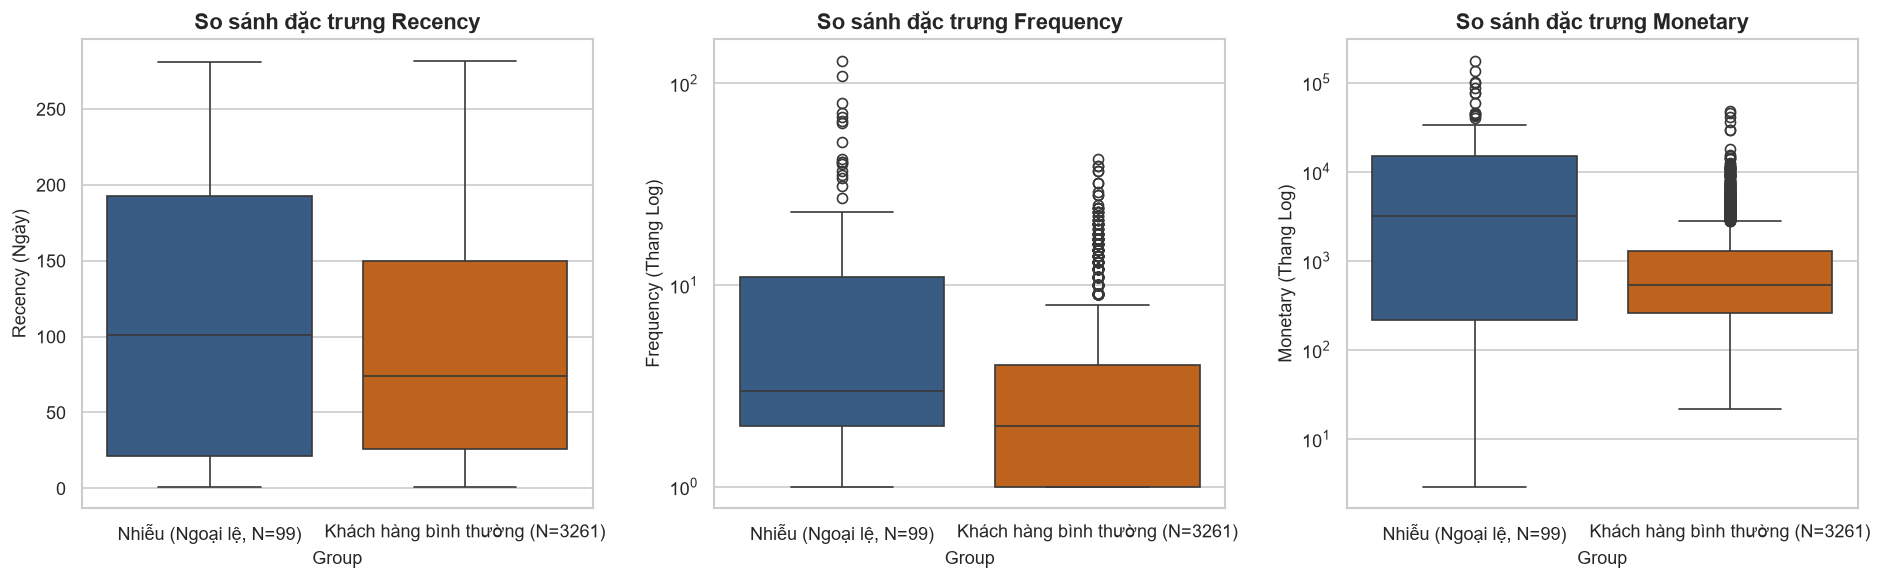

Đã lưu hình phân tích nhóm nhiễu vào: D:\TH-MayHoc\machine_learning\DoAn\reports\figures\dbscan_noise_rfm_profile.png


In [13]:
# Trực quan hóa so sánh phân phối trên thang đo Log
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    sns.boxplot(
        data=df_analysis, x='Group', y=col, ax=axes[i],
        palette=['#2b5c8f', '#d95f02']
    )
    axes[i].set_title(f"So sánh đặc trưng {col}", fontweight='bold')
    if col in ['Frequency', 'Monetary']:
        axes[i].set_yscale('log')
        axes[i].set_ylabel(f"{col} (Thang Log)")
    else:
        axes[i].set_ylabel(f"{col} (Ngày)")

plt.tight_layout()
fig_noise = FIGURES_DIR / "dbscan_noise_rfm_profile.png"
plt.savefig(fig_noise, bbox_inches='tight', dpi=150)
plt.show()
print(f"Đã lưu hình phân tích nhóm nhiễu vào: {fig_noise}")

### Nhận Xét Hồ Sơ Nhóm Nhiễu Của DBSCAN:
1. **Giá trị đơn hàng và chi tiêu cực lớn (Wholesale B2B)**:
   - Nhóm nhiễu sở hữu mức chi tiêu `Monetary` trung bình lên tới **15.556 GBP** (so với nhóm bình thường chỉ là **1.163 GBP** - gấp hơn **13 lần**!). Khách hàng cao nhất trong nhóm đạt tới **177.729 GBP**.
   - Giá trị đơn hàng trung bình `AvgOrderValue` đạt **2.329 GBP** (so với nhóm bình thường là **337 GBP** - gấp gần **7 lần**).
   - Tần suất mua hàng `Frequency` đạt trung bình **13.5 đơn** (so với nhóm bình thường là **3.2 đơn**).
2. **Bản chất kinh doanh**:
   - Đây chính là các **khách hàng mua buôn / mua sỉ (Wholesale B2B)** hoặc các **tài khoản tổ chức**.
   - DBSCAN đã thực hiện xuất sắc nhiệm vụ nhận diện các khách hàng có hành vi dị biệt mà không ép buộc họ vào các cụm khách lẻ thông thường. Trong thực tế quản trị quan hệ khách hàng (CRM), nhóm này cần được chuyển giao cho đội ngũ chăm sóc khách hàng doanh nghiệp (Key Account Management) phụ trách riêng với chính sách chiết khấu hợp đồng đặc thù.

---
## 6. So Sánh Bản Chất Gom Cụm Giữa Hierarchical, DBSCAN và K-Means

| Đặc tính so sánh | K-Means | Hierarchical (Ward Linkage) | DBSCAN |
| :--- | :--- | :--- | :--- |
| **Bản chất thuật toán** | Phân hoạch (Partitioning) tối ưu hóa trọng tâm | Phân cấp (Agglomerative) gộp cụm từ dưới lên | Mật độ không gian (Density-based) kết nối các vùng dày đặc |
| **Hình học cụm giả định** | Cụm hình cầu lồi (convex spherical), kích thước cân bằng | Cụm cân bằng, hình cầu lồi (với Ward) | Tự do, bất kỳ hình dạng nào (arbitrary / non-convex) |
| **Xác định số cụm** | Bắt buộc ấn định trước $k$ | Cắt cây Dendrogram linh hoạt sau khi xây dựng | Tự động phát hiện qua bán kính $\varepsilon$ và $MinPts$ |
| **Xử lý ngoại lệ / Nhiễu** | Kém: Ép mọi điểm ngoại lệ vào cụm gần nhất, làm méo mó tâm cụm | Kém: Điểm ngoại lệ bị gộp muộn làm tăng đột biến khoảng cách | **Tuyệt vời**: Tự động cô lập ngoại lệ thành nhãn -1 |
| **Độ ổn định (Tính tất định)** | Không tất định (phụ thuộc khởi tạo ngẫu nhiên `k-means++`) | Hoàn toàn tất định (kết quả lặp lại 100%) | Hoàn toàn tất định với điểm lõi và nhiễu |
| **Độ phức tạp tính toán** | Tuyến tính $O(t \cdot k \cdot N \cdot D)$, rất nhanh | $O(N^2 \log N)$ đến $O(N^3)$, bộ nhớ $O(N^2)$ | $O(N \log N)$ với k-d tree, $O(N^2)$ số chiều cao |
| **Ứng dụng tối ưu trong dự án** | Phân khúc thị trường đại chúng cân bằng để triển khai Marketing | Xây dựng phả hệ khách hàng và thẩm định số cụm $k$ tối ưu | Lọc khách hàng mua sỉ / giao dịch bất thường (Wholesale) |

In [14]:
print("=== HOÀN THÀNH TOÀN BỘ TIẾN TRÌNH NOTEBOOK 03B ===")
print("Các bảng kết quả đã xuất tại reports/tables/:")
for p in sorted(TABLES_DIR.glob('*hierarchical*.csv')) + sorted(TABLES_DIR.glob('*dbscan*.csv')):
    print(" -", p.name)

=== HOÀN THÀNH TOÀN BỘ TIẾN TRÌNH NOTEBOOK 03B ===
Các bảng kết quả đã xuất tại reports/tables/:
 - labels_hierarchical_rfm_k2_ward.csv
 - labels_hierarchical_rfm_k3_ward.csv
 - labels_hierarchical_rfm_k4_ward.csv
 - tuning_hierarchical.csv
 - labels_dbscan_rfm_eps0_5_min10.csv
 - labels_dbscan_rfm_plus_eps0_8_min10.csv
 - labels_dbscan_rfm_plus_eps0_8_min14.csv
 - tuning_dbscan.csv
